# Goodreads Best Books Ever – Veri Seti Keşif Analizi

In [2]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_PATH = (
    PROJECT_ROOT
    / "data"
    / "metadata"
    / "books_1.Best_Books_Ever.csv"
)

goodreads_df = pd.read_csv(
    DATASET_PATH,
    low_memory=False
)

print("Veri seti boyutu:", goodreads_df.shape)

print("\nSütun isimleri:")
print(goodreads_df.columns.tolist())

print("\nİlk 5 kitap:")
display(
    goodreads_df[
        ["bookId", "title", "genres", "coverImg"]
    ].head()
)

Veri seti boyutu: (52478, 25)

Sütun isimleri:
['bookId', 'title', 'series', 'author', 'rating', 'description', 'language', 'isbn', 'genres', 'characters', 'bookFormat', 'edition', 'pages', 'publisher', 'publishDate', 'firstPublishDate', 'awards', 'numRatings', 'ratingsByStars', 'likedPercent', 'setting', 'coverImg', 'bbeScore', 'bbeVotes', 'price']

İlk 5 kitap:


,bookId,title,genres,coverImg
0,2767052-the-hunger-games,The Hunger Games,"['Young Adult', 'Fiction', 'Dystopia', 'Fantas...",https://i.gr-assets.com/images/S/compressed.ph...
1,2.Harry_Potter_and_the_Order_of_the_Phoenix,Harry Potter and the Order of the Phoenix,"['Fantasy', 'Young Adult', 'Fiction', 'Magic',...",https://i.gr-assets.com/images/S/compressed.ph...
2,2657.To_Kill_a_Mockingbird,To Kill a Mockingbird,"['Classics', 'Fiction', 'Historical Fiction', ...",https://i.gr-assets.com/images/S/compressed.ph...
3,1885.Pride_and_Prejudice,Pride and Prejudice,"['Classics', 'Fiction', 'Romance', 'Historical...",https://i.gr-assets.com/images/S/compressed.ph...
4,41865.Twilight,Twilight,"['Young Adult', 'Fantasy', 'Romance', 'Vampire...",https://i.gr-assets.com/images/S/compressed.ph...


In [3]:
# Bütün sütunlardaki eksik değer sayıları
missing_values = goodreads_df.isna().sum()

missing_percent = (
    missing_values / len(goodreads_df) * 100
).round(2)

missing_analysis = pd.DataFrame({
    "Eksik Sayısı": missing_values,
    "Eksik Yüzdesi": missing_percent
})

display(missing_analysis)

print("\nToplam kayıt:", len(goodreads_df))

print(
    "Tür bilgisi bulunan:",
    goodreads_df["genres"].notna().sum()
)

print(
    "Kapak URL'si bulunan:",
    goodreads_df["coverImg"].notna().sum()
)

print(
    "Hem tür hem kapak URL'si bulunan:",
    goodreads_df[
        ["genres", "coverImg"]
    ].notna().all(axis=1).sum()
)

print(
    "Tekrarlanan kitap kimliği:",
    goodreads_df["bookId"].duplicated().sum()
)

,Eksik Sayısı,Eksik Yüzdesi
bookId,0,0.00
title,0,0.00
series,29008,55.28
author,0,0.00
rating,0,0.00
description,1338,2.55
language,3806,7.25
isbn,0,0.00
genres,0,0.00
characters,0,0.00



Toplam kayıt: 52478
Tür bilgisi bulunan: 52478
Kapak URL'si bulunan: 51873
Hem tür hem kapak URL'si bulunan: 51873
Tekrarlanan kitap kimliği: 54


In [4]:
import ast
from collections import Counter

def parse_genres(value):
    if pd.isna(value):
        return []

    try:
        genres = ast.literal_eval(value)

        if isinstance(genres, list):
            return genres

    except (ValueError, SyntaxError, TypeError):
        pass

    return []

goodreads_df["genre_list"] = (
    goodreads_df["genres"].apply(parse_genres)
)

genre_counts = Counter(
    genre
    for genres in goodreads_df["genre_list"]
    for genre in genres
)

print("Benzersiz tür sayısı:", len(genre_counts))

print("\nEn yaygın 20 tür:")

for genre, count in genre_counts.most_common(20):
    print(f"{genre}: {count}")

Benzersiz tür sayısı: 982

En yaygın 20 tür:
Fiction: 31638
Romance: 15495
Fantasy: 15046
Young Adult: 11869
Contemporary: 10520
Nonfiction: 8251
Adult: 8246
Novels: 7805
Mystery: 7702
Historical Fiction: 7665
Audiobook: 7307
Classics: 6902
Adventure: 6452
Historical: 6383
Paranormal: 6030
Literature: 5836
Science Fiction: 5374
Childrens: 5226
Thriller: 4587
Magic: 4248


## Tür ve Kapak URL Kalite Kontrolleri / Genre and Cover URL Quality Checks

In [10]:
# Tür listelerinin kullanılabilirliğini kontrol et
empty_genres = goodreads_df["genre_list"].apply(
    lambda genres: len(genres) == 0
).sum()

# Geçerli URL biçimini kontrol et
valid_url = (
    goodreads_df["coverImg"]
    .fillna("")
    .str.startswith(("http://", "https://"))
)

# Hem tür hem URL koşulunu sağlayan kayıtlar
usable_records = (
    (goodreads_df["genre_list"].apply(len) > 0)
    & valid_url
)

print("Boş veya ayrıştırılamayan tür listesi:", empty_genres)
print("URL biçimi geçerli kayıt:", valid_url.sum())
print("Tür listesi ve URL koşulunu sağlayan:", usable_records.sum())

# Tekrarlanan kitap kimliklerini incele
print("\nTekrarlanan kimliklere ait örnek kayıtlar:")

display(
    goodreads_df[
        goodreads_df["bookId"].duplicated(keep=False)
    ][["bookId", "title", "genres"]].head(10)
)

Boş veya ayrıştırılamayan tür listesi: 4623
URL biçimi geçerli kayıt: 51873
Tür listesi ve URL koşulunu sağlayan: 47571

Tekrarlanan kimliklere ait örnek kayıtlar:


,bookId,title,genres
37377,8794263-promises-to-keep,Promises to Keep,"['Fiction', 'Christian Fiction', 'Christian', ..."
37378,1909590.Click,Click,"['Young Adult', 'Fiction', 'Short Stories', 'M..."
37379,23394408-die-unendlichkeit-schl-ft,Die Unendlichkeit schläft,[]
37380,7544945-death-note,"Death Note: Black Edition, Vol. 2","['Graphic Novels', 'Comics', 'Fantasy', 'Manga..."
37381,25886017-m-scaras,Máscaras,"['Fiction', 'Literature']"
37382,2669775-el-siglo-de-las-luces,El siglo de las luces,"['Fiction', 'Spanish Literature', 'Historical ..."
37383,24633605-always-and-forever,Always and Forever,"['Contemporary Romance', 'Romance', 'Firefight..."
37384,237086.Dafne_desvanecida,Dafne desvanecida,"['Fiction', 'Mystery', 'Contemporary', 'Spanis..."
37385,17786377,فضولية العلم,"['Science', 'Nonfiction']"
37386,7452583-jag-vill-inte-d-jag-vill-bara-inte-leva,"Jag vill inte dö, jag vill bara inte leva","['Nonfiction', 'Psychology', 'Biography', 'Men..."


## Goodreads Tür Dağılımı Görselleştirmesi / Goodreads Genre Distribution Visualization

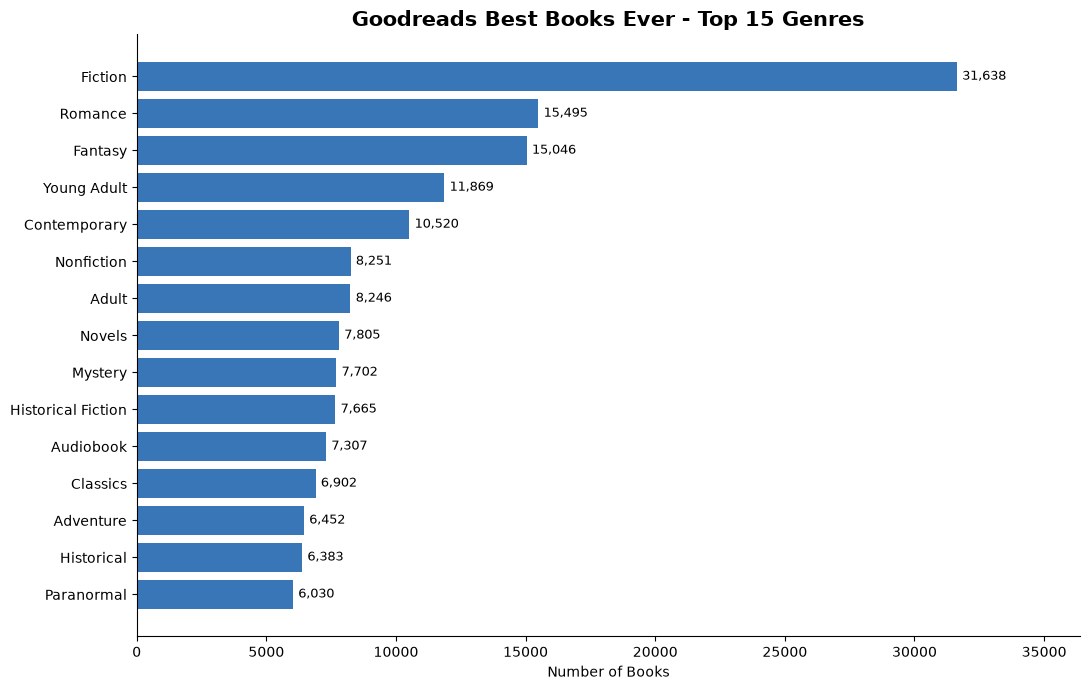

In [6]:
import matplotlib.pyplot as plt
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# En yaygın 15 türü al
top_genres = genre_counts.most_common(15)

genres = [genre for genre, count in top_genres]
counts = [count for genre, count in top_genres]

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    genres[::-1],
    counts[::-1],
    color="#3976B8"
)

for bar in bars:
    ax.text(
        bar.get_width() + 200,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width()):,}",
        va="center",
        fontsize=9
    )

ax.set_xlim(0, max(counts) * 1.15)
ax.set_xlabel("Number of Books")
ax.set_title(
    "Goodreads Best Books Ever - Top 15 Genres",
    fontsize=15,
    fontweight="bold"
)

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "goodreads_genre_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Kapak Görseli URL Kullanılabilirliği / Cover Image URL Availability

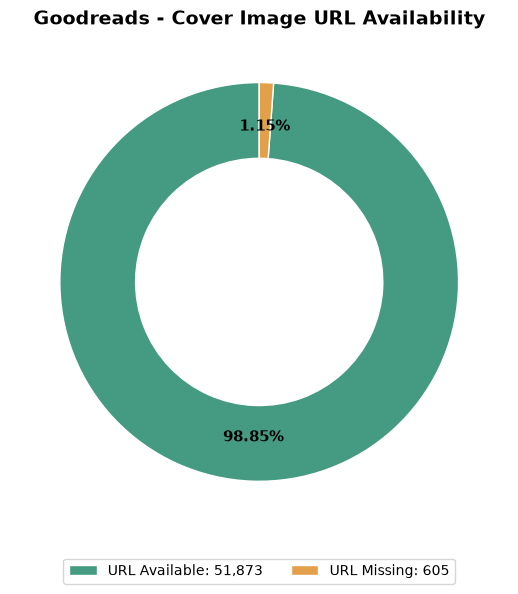

In [7]:
total_books = len(goodreads_df)

available = goodreads_df["coverImg"].notna().sum()
missing = total_books - available

values = [available, missing]
labels = ["URL Available", "URL Missing"]
colors = ["#459B81", "#E3A04B"]

fig, ax = plt.subplots(figsize=(8, 6))

wedges, _, autotexts = ax.pie(
    values,
    colors=colors,
    startangle=90,
    autopct="%1.2f%%",
    pctdistance=0.78,
    wedgeprops={"width": 0.38, "edgecolor": "white"}
)

for text in autotexts:
    text.set_fontsize(11)
    text.set_fontweight("bold")

ax.legend(
    wedges,
    [f"{label}: {value:,}" for label, value in zip(labels, values)],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2
)

ax.set_title(
    "Goodreads - Cover Image URL Availability",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "goodreads_cover_url_availability.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [8]:
""" URL bulunması, görselin gerçekten indirilebilir olduğunu garanti etmez. İndirme başarısını daha sonra ayrıca ölçeceğiz. """

' URL bulunması, görselin gerçekten indirilebilir olduğunu garanti etmez. İndirme başarısını daha sonra ayrıca ölçeceğiz. '

## Eksik metadata analizi /  Missing Metadata Visualization

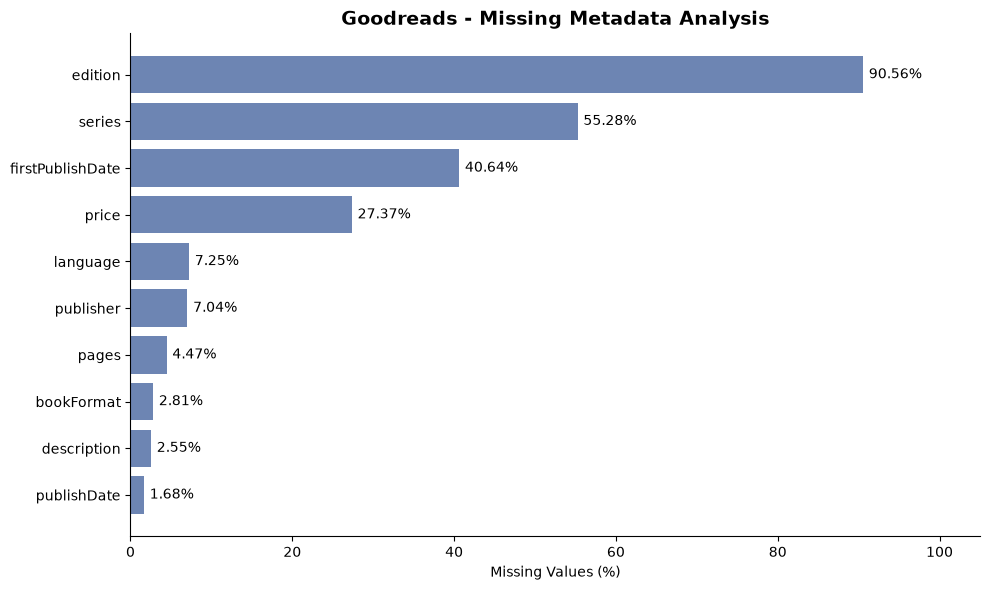

In [9]:
missing_percent = (
    goodreads_df.isna().mean() * 100
).sort_values(ascending=False)

# Eksik değeri bulunan ilk 10 sütun
top_missing = missing_percent[
    missing_percent > 0
].head(10)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top_missing.index[::-1],
    top_missing.values[::-1],
    color="#6D85B3"
)

for bar in bars:
    ax.text(
        bar.get_width() + 0.7,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center",
        fontsize=10
    )

ax.set_xlim(0, 105)
ax.set_xlabel("Missing Values (%)")
ax.set_title(
    "Goodreads - Missing Metadata Analysis",
    fontsize=14,
    fontweight="bold"
)

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "goodreads_missing_values.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()